# Итоговый проект

**Тема:** Исследование влияния понижения размерности на кластеризацию изображений рукописных цифр.

**Датасет:** `digits` из `sklearn.datasets`. В наборе 1797 изображений размером 8×8 пикселей. Каждый пиксель является отдельным признаком, поэтому исходная размерность равна 64. В наборе представлены цифры от 0 до 9.

Цель проекта - сравнить несколько способов понижения размерности и алгоритмов кластеризации. Правильные ответы не участвуют в обучении моделей: они понадобятся только в конце для оценки и интерпретации.

## 1. Загрузка данных и знакомство с ними

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score, normalized_mutual_info_score
)

random_state = 42
digits = load_digits()
X = digits.data
y_true = digits.target

print("Размер данных:", X.shape)
print("Количество цифр:", len(np.unique(y_true)))
print("Значения пикселей:", X.min(), "-", X.max())

Размер данных: (1797, 64)
Количество цифр: 10
Значения пикселей: 0.0 - 16.0


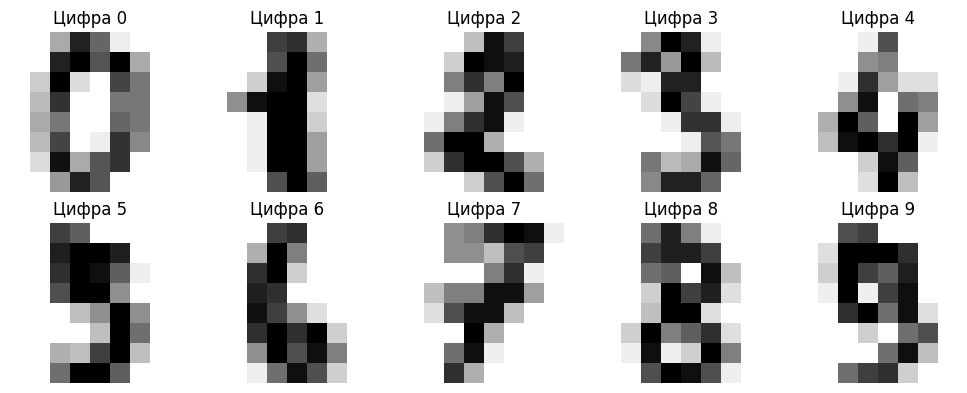

In [20]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.flat):
    image_index = np.where(y_true == digit)[0][0]
    ax.imshow(digits.images[image_index], cmap="gray_r")
    ax.set_title(f"Цифра {digit}")
    ax.axis("off")
plt.tight_layout()
plt.show()

На изображении видно, что цифры написаны разными людьми, поэтому один и тот же класс может выглядеть по-разному. Это усложняет кластеризацию: близкие по форме цифры могут оказаться рядом.

## 2. Подготовка данных и уменьшение размерности

In [21]:
# Масштабируем признаки, чтобы все пиксели имели сопоставимый вес.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA оставляет 30 главных компонент для последующей кластеризации.
pca = PCA(n_components=30, random_state=random_state)
X_pca = pca.fit_transform(X_scaled)
print("Размерность после PCA:", X_pca.shape)
print("Доля сохраненной дисперсии:", round(pca.explained_variance_ratio_.sum(), 3))

# t-SNE используем для двумерной визуализации.
tsne = TSNE(n_components=2, perplexity=30, init="pca",
            learning_rate="auto", random_state=random_state)
X_tsne = tsne.fit_transform(X_pca)

Размерность после PCA: (1797, 30)
Доля сохраненной дисперсии: 0.893


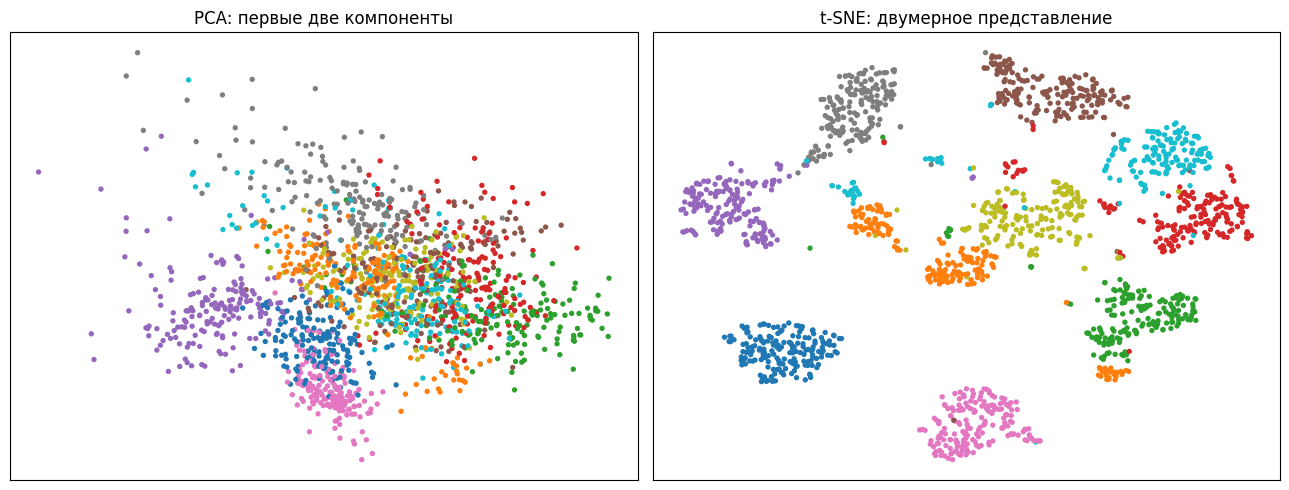

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap="tab10", s=8)
axes[0].set_title("PCA: первые две компоненты")
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_true, cmap="tab10", s=8)
axes[1].set_title("t-SNE: двумерное представление")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

На графиках цвет показывает настоящую цифру, но модели эти метки не получают. Первые две компоненты PCA сохраняют только часть информации. t-SNE обычно лучше разделяет локальные группы, однако расстояния между отдельными группами на этой карте нельзя трактовать как точные расстояния в исходных данных.

## 3. Кластеризация

In [23]:
# Для сравнения используем одинаковое представление PCA.
models = {
    "KMeans": KMeans(n_clusters=10, n_init=10, random_state=random_state),
    "Agglomerative": AgglomerativeClustering(n_clusters=10),
    "DBSCAN": DBSCAN(eps=4.0, min_samples=8)
}

cluster_labels = {}
for name, model in models.items():
    cluster_labels[name] = model.fit_predict(X_pca)
    print(name, "число кластеров:", len(set(cluster_labels[name]) - {-1}))
    print("шум (кол-во точек):", np.sum(cluster_labels[name] == -1))
    print()

KMeans число кластеров: 10
шум (кол-во точек): 0

Agglomerative число кластеров: 10
шум (кол-во точек): 0

DBSCAN число кластеров: 5
шум (кол-во точек): 296



## 4. Оценка качества

In [24]:
def evaluate_clustering(X_data, labels, true_labels):
    # Для DBSCAN исключаем шум при расчете внутренних метрик.
    mask = labels != -1
    regular_labels = labels[mask]
    unique_labels = np.unique(regular_labels)

    result = {
        "кластеров": len(unique_labels),
        "шум (кол-во точек)": int(np.sum(labels == -1)),
        "ARI": adjusted_rand_score(true_labels, labels),
        "NMI": normalized_mutual_info_score(true_labels, labels)
    }
    if len(unique_labels) > 1 and mask.sum() > len(unique_labels):
        result["Silhouette"] = silhouette_score(X_data[mask], regular_labels)
        result["Davies-Bouldin"] = davies_bouldin_score(X_data[mask], regular_labels)
        result["Calinski-Harabasz"] = calinski_harabasz_score(X_data[mask], regular_labels)
    else:
        result["Silhouette"] = np.nan
        result["Davies-Bouldin"] = np.nan
        result["Calinski-Harabasz"] = np.nan
    return result

rows = []
for name, labels in cluster_labels.items():
    row = evaluate_clustering(X_pca, labels, y_true)
    row["Алгоритм"] = name
    rows.append(row)

results = pd.DataFrame(rows).set_index("Алгоритм")
results.round(3)

,кластеров,шум (кол-во точек),ARI,NMI,Silhouette,Davies-Bouldin,Calinski-Harabasz
Алгоритм,,,,,,,
KMeans,10,0,0.476,0.631,0.175,1.708,137.360
Agglomerative,10,0,0.666,0.792,0.150,1.772,126.452
DBSCAN,5,296,0.047,0.222,0.030,1.504,48.475


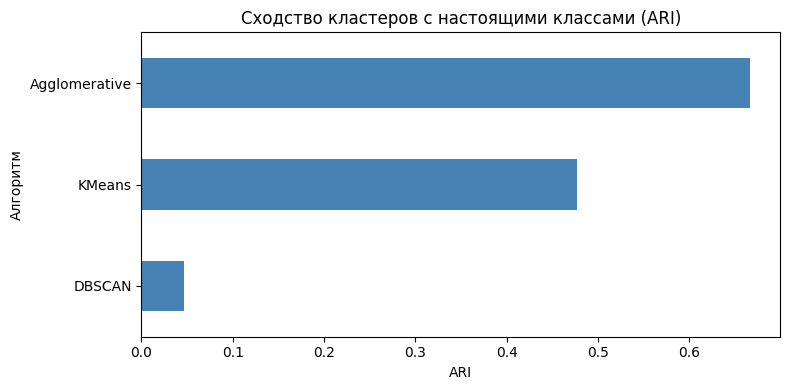

In [25]:
fig, ax = plt.subplots(figsize=(8, 4))
results["ARI"].sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Сходство кластеров с настоящими классами (ARI)")
ax.set_xlabel("ARI")
plt.tight_layout()
plt.show()

Внутренние метрики оценивают компактность и разделенность кластеров без знания правильных классов. ARI и NMI позволяют дополнительно посмотреть, насколько найденное разбиение совпадает с цифрами. Метрики не всегда выбирают один и тот же алгоритм, поэтому вывод делаем по совокупности показателей.

## 5. Устойчивость KMeans

In [26]:
# Меняем начальное состояние и сравниваем разбиения по ARI.
stability_labels = []
for seed in [1, 7, 21, 42, 100]:
    model = KMeans(n_clusters=10, n_init=10, random_state=seed)
    stability_labels.append(model.fit_predict(X_pca))

stability_scores = []
for i in range(len(stability_labels)):
    for j in range(i + 1, len(stability_labels)):
        stability_scores.append(adjusted_rand_score(
            stability_labels[i], stability_labels[j]
        ))

print("Средний ARI между запусками:", round(np.mean(stability_scores), 3))
print("Минимальный ARI между запусками:", round(np.min(stability_scores), 3))

Средний ARI между запусками: 0.893
Минимальный ARI между запусками: 0.827


ARI близкий к 1 между запусками означает, что алгоритм чаще возвращает похожие разбиения при разных начальных состояниях. Это простой вариант проверки устойчивости; он не проверяет, как результат изменится при добавлении новых изображений.

## 6. Интерпретация кластеров

In [27]:
# Покажем, какие настоящие цифры чаще попали в каждый кластер KMeans.
cluster_digit_table = pd.crosstab(
    cluster_labels["KMeans"], y_true,
    rownames=["Кластер"], colnames=["Настоящая цифра"]
)
cluster_digit_table

Настоящая цифра,0,1,2,3,4,5,6,7,8,9
Кластер,,,,,,,,,,
0,0,97,39,8,3,24,4,0,97,3
1,0,0,5,159,0,76,0,0,46,146
2,0,0,0,0,9,0,0,17,0,3
3,1,0,0,0,157,2,0,0,0,0
4,177,0,0,0,0,0,1,0,0,0
5,0,0,1,7,4,5,0,151,2,8
6,0,27,48,2,0,0,0,0,0,0
7,0,0,0,0,0,4,175,0,3,0
8,0,58,4,0,7,3,1,3,15,19


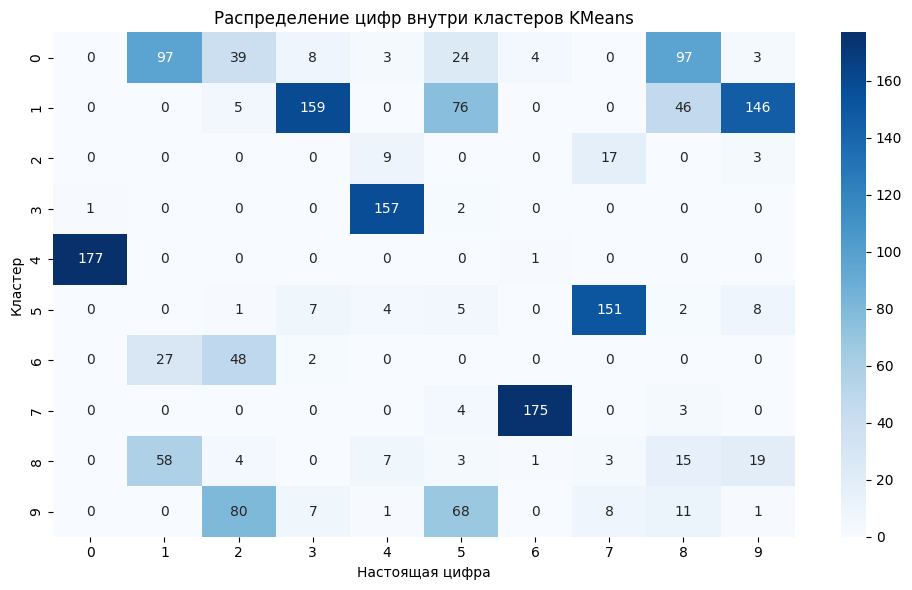

In [28]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(cluster_digit_table, cmap="Blues", annot=True, fmt="d", ax=ax)
ax.set_title("Распределение цифр внутри кластеров KMeans")
plt.tight_layout()
plt.show()

Таблица показывает состав каждого найденного кластера. Если в строке преобладает одна цифра, кластер можно считать относительно понятным. Смешанные строки могут появляться у похожих по написанию цифр или из-за различий почерка.

## Выводы

В проекте исследован набор рукописных цифр `digits` с 64 признаками. После стандартизации PCA сократил размерность до 30 компонент, сохранив большую часть вариации данных; t-SNE использован для визуального изучения структуры.

Сравнение KMeans, агломеративной кластеризации и DBSCAN показывает, что результат зависит от выбранного алгоритма и метрики. Для DBSCAN особенно важны параметры `eps` и `min_samples`: он может выделить шум и получить число групп, отличающееся от десяти. KMeans и агломеративная модель, напротив, заранее строят ровно десять кластеров.

Настоящие метки цифр не использовались при обучении. Их применение для ARI, NMI и таблицы состава кластеров помогло оценить результат и увидеть, какие цифры смешиваются. Проверка нескольких запусков KMeans дает представление об устойчивости разбиения. Для более полного исследования можно отдельно подобрать параметры DBSCAN и сравнить результаты при других размерах PCA.